In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [7]:
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


Part 1: Understanding Product Categories

In [9]:
# 1: count categories
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
# 2: top 5 categories
df["category"].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

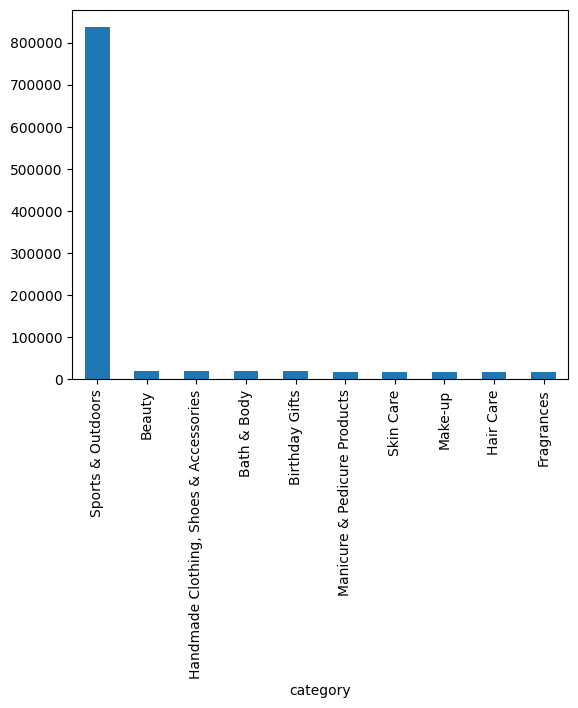

In [11]:
# 3: bar chart
df["category"].value_counts().head(10).plot(kind="bar")
plt.show()

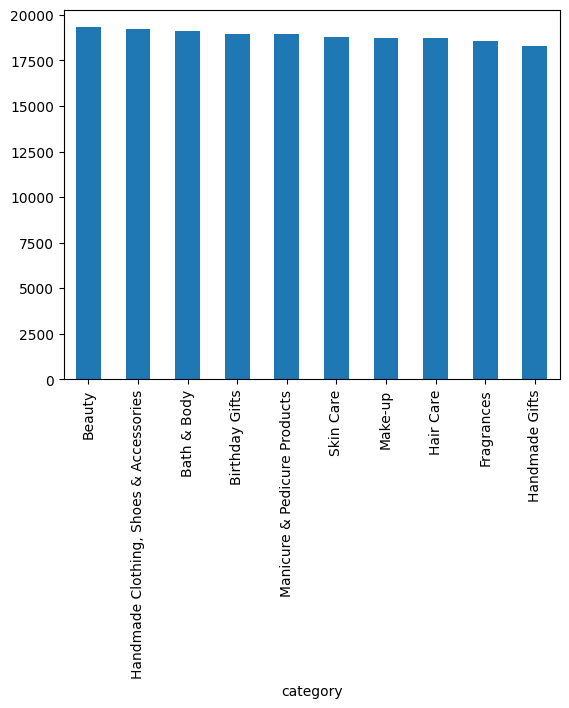

In [12]:
# 4: remove dominant category
top_categories = df["category"].value_counts().drop("Sports & Outdoors").head(10)

top_categories.plot(kind="bar")
plt.show()

* One category (Sports & Outdoors) dominates the dataset significantly
* The remaining categories are relatively evenly distributed
* Removing the dominant category helps reveal this pattern

Part 2: Delving into Product Pricing

In [13]:
# 1: centrality measures
df["price"].mean()
df["price"].median()
df["price"].mode()

0    9.99
Name: price, dtype: float64

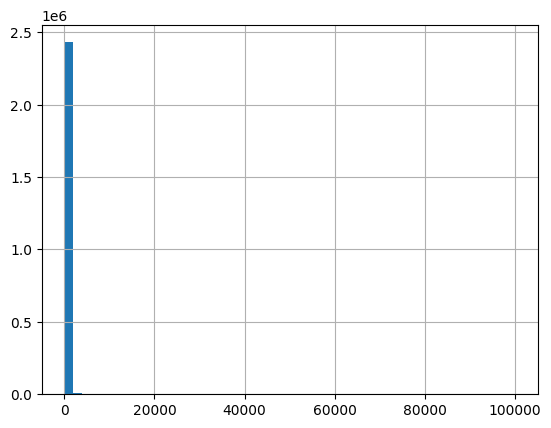

In [14]:
# 2: histogram
df["price"].hist(bins=50)
plt.show()

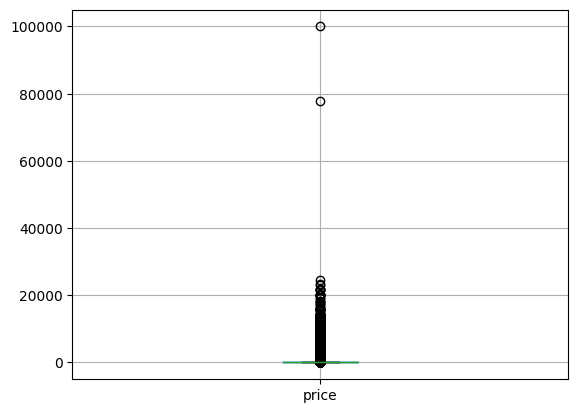

In [15]:
# 3: boxplot
df.boxplot(column="price")
plt.show()

* Prices are highly right-skewed
* The mean is much higher than the median
* There are significant outliers
* The histogram is hard to interpret due to extreme values

In [16]:
# 4: filter extreme prices
df_filtered = df[df["price"] < 500]

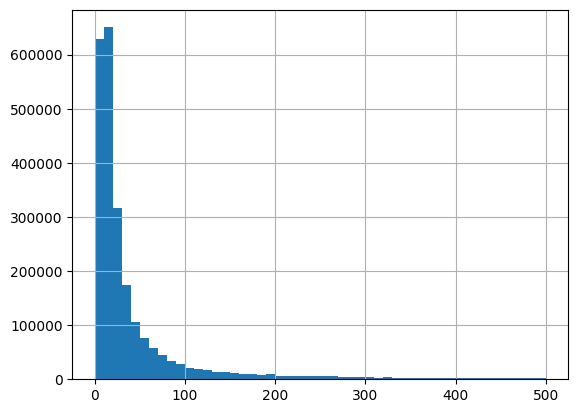

In [17]:
df_filtered["price"].hist(bins=50)
plt.show()

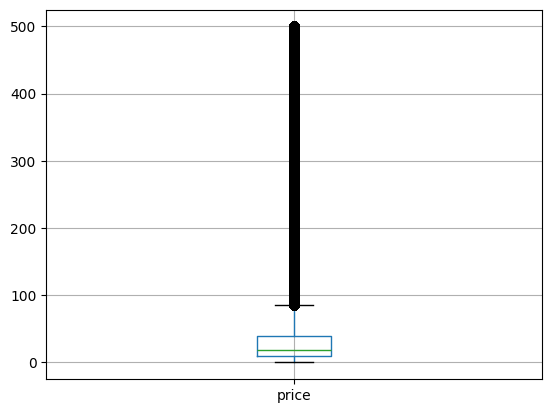

In [18]:
df_filtered.boxplot(column="price")
plt.show()

* Prices are heavily right-skewed
* Most products are priced in the low price range (0–20)
* There are many high-price outliers
* Filtering improves interpretability

Part 3: Unpacking Product Ratings

In [19]:
# 1: rating stats
df["stars"].mean()
df["stars"].median()
df["stars"].mode()

0    0.0
Name: stars, dtype: float64

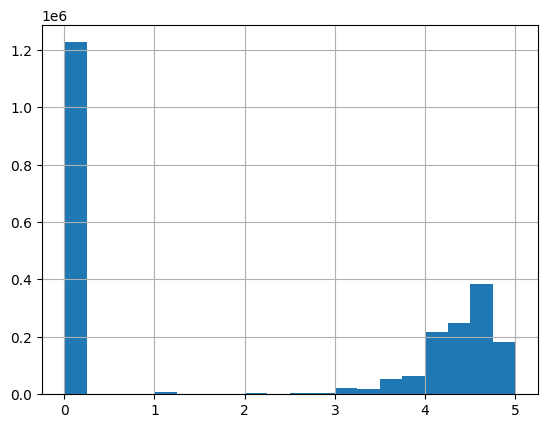

In [20]:
# 2: rating distribution
df["stars"].hist(bins=20)
plt.show()

In [21]:
# 3: dispersion
df["stars"].std()
df["stars"].var()

np.float64(4.817434029796864)

In [22]:
# 4: skewness
df["stars"].skew()

np.float64(0.08120735761080881)

In [23]:
# 5: filter real ratings
df_ratings = df[df["stars"] > 0]

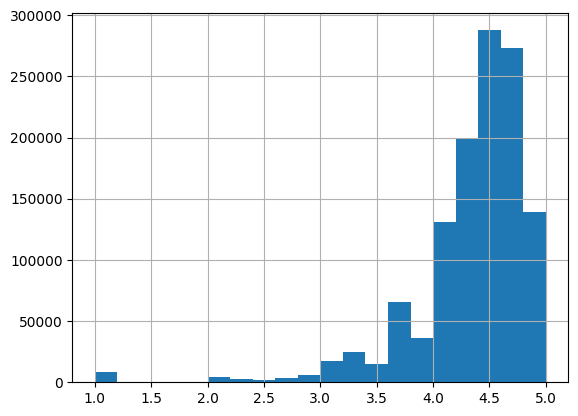

In [24]:
df_ratings["stars"].hist(bins=20)
plt.show()

In [25]:
df_ratings["stars"].skew()

np.float64(-2.379568112212799)

In [26]:
df_ratings["stars"].describe()

count    1.218010e+06
mean     4.319161e+00
std      5.552868e-01
min      1.000000e+00
25%      4.100000e+00
50%      4.400000e+00
75%      4.600000e+00
max      5.000000e+00
Name: stars, dtype: float64

* Ratings are highly concentrated in the upper range (4–5 stars)
* The distribution is left-skewed
* Most products receive positive reviews
* Very few products have low ratings

* Categories: The strong dominance of 'Sports & Outdoors' suggests a high supply (and potentially strong demand?) in this category, making it a competitve but important segment for sellers.
* Price: The majority of products are priced at the lower end, indicating a price-sensitive market where competitive pricing may be key for success.
* Ratings: Most products have high ratings, which suggests generally positive customer satisfaction, but also implies that differentiation based on ratings alone may be difficult.
